In [2]:
from data import load_synth, load_mnist

In [3]:
import math

# inputs and target
x = [1., -1.]
target = 0                      # true class

# layer 1: 2 inputs -> 3 hidden
W = [[1., 1., 1.],
     [-1., -1., -1.]]           # W[i][j]: from input i to hidden j
b = [0., 0., 0.]

# layer 2: 3 hidden -> 2 outputs
V = [[1., 1.],
     [-1., -1.],
     [-1., -1.]]                # V[j][m]: from hidden j to output m
c = [0., 0.]

Q3 FORWARD PASS

In [4]:
k = [0., 0., 0.]
for j in range(3):
    for i in range(2):
        k[j] += x[i] * W[i][j]
    k[j] += b[j]
print(k)

[2.0, 2.0, 2.0]


In [5]:
h = [0., 0., 0.]
for j in range(3):
    h[j] = 1 / (1 + math.exp(-k[j]))
print(h)

[0.8807970779778823, 0.8807970779778823, 0.8807970779778823]


In [6]:
o = [0., 0.]
for m in range(2):
    for j in range(3):
        o[m] += h[j] * V[j][m]
    o[m] += c[m]
print(o)

[-0.8807970779778823, -0.8807970779778823]


In [7]:
S = sum(math.exp(o[n]) for n in range(2))
print(S)

0.8289048581695506


In [8]:
y = [math.exp(o[m]) / S for m in range(2)]
print(y)

[0.5, 0.5]


In [9]:
loss = -math.log(y[target])
print(loss)

0.6931471805599453


Q3 BACKWARD PASS

In [10]:
d_o = list(y)
d_o[target] -= 1
print(d_o)

[-0.5, 0.5]


In [11]:
d_c = list(d_o)
print(d_c)

[-0.5, 0.5]


In [12]:
d_V = [[0., 0.], [0., 0.], [0., 0.]]
for j in range(3):
    for m in range(2):
        d_V[j][m] = d_o[m]*h[j]
print(d_V)

[[-0.44039853898894116, 0.44039853898894116], [-0.44039853898894116, 0.44039853898894116], [-0.44039853898894116, 0.44039853898894116]]


In [13]:
d_h = [0., 0., 0.]
for j in range(3):
    for m in range(2):
        d_h[j] += d_o[m] * V[j][m]
print(d_h)

[0.0, 0.0, 0.0]


In [14]:
d_k = [0., 0., 0.]
for j in range(3):
        d_k[j] = d_h[j] * h[j] * (1 - h[j])
print(d_k)

[0.0, 0.0, 0.0]


In [15]:
d_W = [[0., 0., 0.], [0., 0., 0.]]
for i in range(2):
    for j in range(3):
        d_W[i][j] = d_k[j] * x[i]
d_b = list(d_k)
print(d_W)

[[0.0, 0.0, 0.0], [-0.0, -0.0, -0.0]]


In [16]:
print('loss', loss)
print('d_W', d_W)
print('d_b', d_b)
print('d_V', [[round(v, 4) for v in row] for row in d_V])
print('d_c', d_c)

loss 0.6931471805599453
d_W [[0.0, 0.0, 0.0], [-0.0, -0.0, -0.0]]
d_b [0.0, 0.0, 0.0]
d_V [[-0.4404, 0.4404], [-0.4404, 0.4404], [-0.4404, 0.4404]]
d_c [-0.5, 0.5]


In [17]:
(xtrain, ytrain), (xval, yval), num_cls = load_synth()
print(xtrain.shape, ytrain.shape)
print(xtrain[:5])
print(ytrain[:5])

(60000, 2) (60000,)
[[ 1.76405235  0.40015721]
 [ 0.97873798  2.2408932 ]
 [ 1.86755799 -0.97727788]
 [ 0.95008842 -0.15135721]
 [-0.10321885  0.4105985 ]]
[1 1 1 1 0]


In [18]:
import random
random.seed(0)

W = [[0., 0., 0.], [0., 0., 0.]]
for i in range(2):
    for j in range(3):
        W[i][j] = random.gauss(0, 1)

V = [[0., 0.], [0., 0.], [0., 0.]]
for j in range(3):
    for m in range(2):
        V[j][m] = random.gauss(0, 1)

b = [0., 0., 0.]
c = [0., 0.]

print(W)
print(V)

[[0.9417154046806644, -1.3965781047011498, -0.6797144480784211], [0.3705035674606598, -1.016348894188071, -0.07212002278507135]]
[[0.17919648727485687, -0.8310992152709882], [-1.3090373644593587, 0.1938877412491041], [0.9932497035351971, -0.6469816305475048]]


In [19]:
def forward_backward(x, target):
    # forward pass
    k = [0., 0., 0.]
    for j in range(3):
        for i in range(2):
            k[j] += x[i] * W[i][j]
        k[j] += b[j]

    h = [0., 0., 0.]
    for j in range(3):
        h[j] = 1 / (1 + math.exp(-k[j]))

    o = [0., 0.]
    for m in range(2):
        for j in range(3):
            o[m] += h[j] * V[j][m]
        o[m] += c[m]

    S = sum(math.exp(o[n]) for n in range(2))
    y = [math.exp(o[m]) / S for m in range(2)]

    loss = -math.log(y[target])

    # backward pass
    d_o = list(y)
    d_o[target] -= 1

    d_c = list(d_o)
    d_V = [[0., 0.], [0., 0.], [0., 0.]]
    for j in range(3):
        for m in range(2):
            d_V[j][m] = d_o[m] * h[j]

    d_h = [0., 0., 0.]
    for j in range(3):
        for m in range(2):
            d_h[j] += d_o[m] * V[j][m]

    d_k = [0., 0., 0.]
    for j in range(3):
        d_k[j] = d_h[j] * h[j] * (1 - h[j])

    d_W = [[0., 0., 0.], [0., 0., 0.]]
    for i in range(2):
        for j in range(3):
            d_W[i][j] = d_k[j] * x[i]
    d_b = list(d_k)

    return loss, d_W, d_b, d_V, d_c

In [20]:
loss, d_W, d_b, d_V, d_c = forward_backward([1., -1.], 0)
print(loss)

0.43265985778329413


In [21]:
lr = 0.01
for i in range(2):
    for j in range(3):
        W[i][j] -= lr * d_W[i][j]

for m in range(3):
    for n in range(2):
        V[m][n] -= lr * d_V[m][n]

In [22]:
for j in range(3):
    b[j] -= lr * d_b[j]

for k in range(2):
    c[k] -= lr * d_c[k]

In [23]:
lr = 0.01
running_loss = 0.
losses = []

for n in range(len(xtrain)):
    x = xtrain[n]
    target = ytrain[n]

    loss, d_W, d_b, d_V, d_c = forward_backward(x, target)

    for i in range(2):
        for j in range(3):
            W[i][j] -= lr * d_W[i][j]
    for m in range(3):
        for n2 in range(2):
            V[m][n2] -= lr * d_V[m][n2]
    for j in range(3):
        b[j] -= lr * d_b[j]
    for k in range(2):
        c[k] -= lr * d_c[k]

    running_loss += loss
    if (n + 1) % 1000 == 0:           # every 1000 examples
        losses.append(running_loss / 1000)
        print(n + 1, running_loss / 1000)
        running_loss = 0.

1000 0.6990787647469224
2000 0.6683854816217244
3000 0.6482432059894985
4000 0.6190348715106141
5000 0.5708599819011608
6000 0.5271027209686885
7000 0.48193080840800395
8000 0.4314175957231743
9000 0.3786027641963064
10000 0.3402177506068929
11000 0.3161270289209833
12000 0.278573239812284
13000 0.2692143738990439
14000 0.2735823901167457
15000 0.2617237038055537
16000 0.24896427944704239
17000 0.2480165650059517
18000 0.23259794395069558
19000 0.22674066306535676
20000 0.2365497469408282
21000 0.2209057143567784
22000 0.1982564480625138
23000 0.21097450978877663
24000 0.2103839445442842
25000 0.22361358755430402
26000 0.195610187873341
27000 0.21264282812809304
28000 0.2168726143310219
29000 0.1846841053153161
30000 0.21679551657279128
31000 0.17936101088979622
32000 0.19906296346652036
33000 0.19949227582581258
34000 0.20378480580066557
35000 0.19050101047295676
36000 0.1835238803403706
37000 0.1679124631162608
38000 0.21126723970154732
39000 0.19825032418118516
40000 0.1896291462342

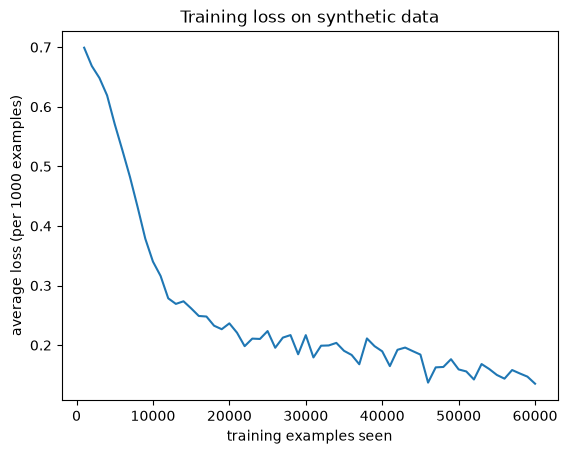

In [24]:
import matplotlib.pyplot as plt

plt.plot(range(1000, 60001, 1000), losses)
plt.xlabel('training examples seen')
plt.ylabel('average loss (per 1000 examples)')
plt.title('Training loss on synthetic data')
plt.savefig('q4_loss.pdf')
plt.show()

In [25]:
import numpy as np

(xtrain, ytrain), (xval, yval), num_cls = load_mnist()
print(xtrain.shape, xtrain.min(), xtrain.max())

(55000, 784) 0 255


In [26]:
xtrain = xtrain / 255
xval = xval / 255
print(xtrain.min(), xtrain.max())

0.0 1.0


In [27]:
np.random.seed(0)
W = np.random.randn(784, 300) / np.sqrt(784)
b = np.zeros(300)
V = np.random.randn(300, 10) / np.sqrt(300)
c = np.zeros(10)

In [28]:
x = xtrain[0]       # shape (784,)
target = ytrain[0]

In [29]:
k = x @ W + b       # (784,) @ (784, 300) -> (300,)

In [30]:
h = 1 / (1 + np.exp(-k))    # (300,)

In [31]:
o = h @ V + c       # (300,) @ (300, 10) -> (10,)

In [32]:
S = np.sum(np.exp(o))

In [33]:
y = np.exp(o) / S    # (10,)

In [34]:
loss = -np.log(y[target])

In [35]:
print(y.sum(), loss)

1.0 2.5987595124356697


Q6 BACKWARD PASS IN NUMPY

In [36]:
d_o = y.copy()
d_o[target] -= 1

In [37]:
d_c = d_o.copy()

In [38]:
d_V = np.outer(h, d_o)    # (300,) outer (10,) -> (300, 10)

In [39]:
d_h = V @ d_o    # (300, 10) @ (10,) -> (300,)

In [40]:
d_k = d_h * h * (1 - h)    # (300,) * (300,) -> (300,)

In [41]:
d_W = np.outer(x, d_k)    # (784,) outer (300,) -> (784, 300)
d_b = d_k.copy()    # (300,)

In [42]:
def forward_backward(x, target):
    # forward
    k = x @ W + b
    h = 1 / (1 + np.exp(-k))
    o = h @ V + c
    S = np.sum(np.exp(o))
    y = np.exp(o) / S
    loss = -np.log(y[target])

    # backward
    d_o = y.copy()
    d_o[target] -= 1
    d_c = d_o.copy()
    d_V = np.outer(h, d_o)
    d_h = V @ d_o
    d_k = d_h * h * (1 - h)
    d_W = np.outer(x, d_k)
    d_b = d_k.copy()

    return loss, d_W, d_b, d_V, d_c

In [43]:
lr = 0.01
running_loss = 0.
losses = []

for n in range(len(xtrain)):
    x = xtrain[n]
    target = ytrain[n]

    loss, d_W, d_b, d_V, d_c = forward_backward(x, target)

    W -= lr * d_W
    b -= lr * d_b
    V -= lr * d_V
    c -= lr * d_c

    running_loss += loss
    if (n + 1) % 5000 == 0:
        losses.append(running_loss / 5000)
        print(n + 1, running_loss / 5000)
        running_loss = 0.

5000 1.0844377004653558
10000 0.47747565625862487
15000 0.39249801128315037
20000 0.3522667634501645
25000 0.35775012383311794
30000 0.33113804573752714
35000 0.33005785887594247
40000 0.3264233606070687
45000 0.30851605883633
50000 0.30667368264956124
55000 0.28757042091153645


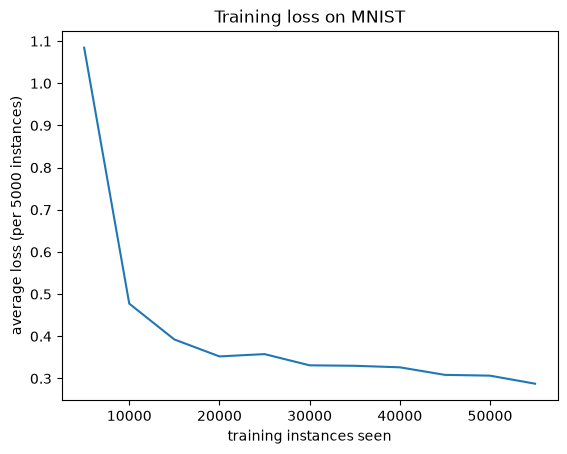

In [44]:
plt.plot(range(5000, 55001, 5000), losses)
plt.xlabel('training instances seen')
plt.ylabel('average loss (per 5000 instances)')
plt.title('Training loss on MNIST')
plt.savefig('q6_loss.pdf')
plt.show()

Q7 BATCHES

In [45]:
# reset to fresh random weights before batched training
np.random.seed(0)
W = np.random.randn(784, 300) / np.sqrt(784)
b = np.zeros(300)
V = np.random.randn(300, 10) / np.sqrt(300)
c = np.zeros(10)

In [46]:
def forward_backward_batch(X, T):
    """X: (B, 784) batch of images, T: (B,) true classes."""
    B = X.shape[0]

    # forward
    K = X @ W + b                              # (B, 300)
    H = 1 / (1 + np.exp(-K))                   # (B, 300)
    O = H @ V + c                              # (B, 10)
    E = np.exp(O)
    S = np.sum(E, axis=1, keepdims=True)       # (B, 1)
    Y = E / S                                  # (B, 10)
    loss = np.mean(-np.log(Y[np.arange(B), T]))

    # backward
    d_O = Y.copy()
    d_O[np.arange(B), T] -= 1
    d_O /= B                                   # (B, 10)
    d_V = H.T @ d_O                            # (300, 10)
    d_c = np.sum(d_O, axis=0)                  # (10,)
    d_H = d_O @ V.T                            # (B, 300)
    d_K = d_H * H * (1 - H)                    # (B, 300)
    d_W = X.T @ d_K                            # (784, 300)
    d_b = np.sum(d_K, axis=0)                  # (300,)

    return loss, d_W, d_b, d_V, d_c

In [47]:
lr = 0.1
batch_size = 32
num_epochs = 1
losses = []                                    # one loss per batch

for epoch in range(num_epochs):
    order = np.random.permutation(len(xtrain))     # shuffle each epoch
    for start in range(0, len(xtrain), batch_size):
        idx = order[start:start + batch_size]
        X = xtrain[idx]
        T = ytrain[idx]

        loss, d_W, d_b, d_V, d_c = forward_backward_batch(X, T)

        W -= lr * d_W
        b -= lr * d_b
        V -= lr * d_V
        c -= lr * d_c

        losses.append(loss)

    print('epoch', epoch + 1, 'average loss', np.mean(losses[-100:]))
print('first batch loss', losses[0])

epoch 1 average loss 0.3543598965884865
first batch loss 2.4192906113381554


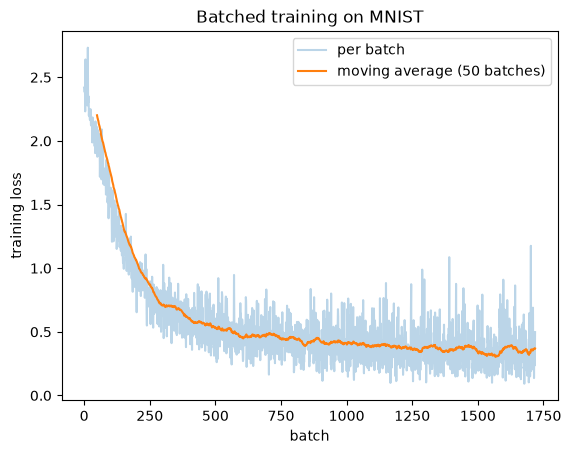

In [48]:
plt.plot(losses, alpha=0.3, label='per batch')
smooth = np.convolve(losses, np.ones(50) / 50, mode='valid')
plt.plot(range(49, len(losses)), smooth, label='moving average (50 batches)')
plt.xlabel('batch')
plt.ylabel('training loss')
plt.title('Batched training on MNIST')
plt.legend()
plt.savefig('q7_loss.pdf')
plt.show()

Q8 MULTIPLE RUNS

In [49]:
def init_weights(seed):
    global W, b, V, c
    np.random.seed(seed)
    W = np.random.randn(784, 300) / np.sqrt(784)
    b = np.zeros(300)
    V = np.random.randn(300, 10) / np.sqrt(300)
    c = np.zeros(10)


def evaluate(X, T):
    """Loss and accuracy on a whole dataset, without training."""
    K = X @ W + b
    H = 1 / (1 + np.exp(-K))
    O = H @ V + c
    E = np.exp(O)
    Y = E / np.sum(E, axis=1, keepdims=True)
    loss = np.mean(-np.log(Y[np.arange(len(T)), T]))
    acc = np.mean(np.argmax(Y, axis=1) == T)
    return loss, acc


def train(lr, seed, xtr, ytr, xev, yev, num_epochs=5, batch_size=32):
    global W, b, V, c
    init_weights(seed)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        order = np.random.permutation(len(xtr))
        for start in range(0, len(xtr), batch_size):
            idx = order[start:start + batch_size]
            loss, d_W, d_b, d_V, d_c = forward_backward_batch(xtr[idx], ytr[idx])
            W -= lr * d_W
            b -= lr * d_b
            V -= lr * d_V
            c -= lr * d_c

        # after each epoch: measure on the full training and validation sets
        tl, ta = evaluate(xtr, ytr)
        vl, va = evaluate(xev, yev)
        hist['train_loss'].append(tl)
        hist['val_loss'].append(vl)
        hist['train_acc'].append(ta)
        hist['val_acc'].append(va)
        print(f'epoch {epoch + 1}: train loss {tl:.4f}, val loss {vl:.4f}, val acc {va:.4f}')

    return hist

In [50]:
hist = train(0.1, 0, xtrain, ytrain, xval, yval)

epoch 1: train loss 0.3446, val loss 0.3485, val acc 0.8940
epoch 2: train loss 0.3002, val loss 0.3126, val acc 0.9078
epoch 3: train loss 0.2703, val loss 0.2794, val acc 0.9174
epoch 4: train loss 0.2499, val loss 0.2603, val acc 0.9266
epoch 5: train loss 0.2213, val loss 0.2318, val acc 0.9332


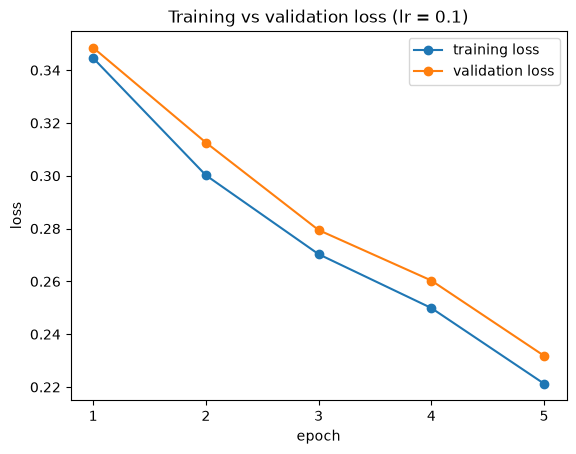

In [51]:
epochs = range(1, 6)
plt.plot(epochs, hist['train_loss'], marker='o', label='training loss')
plt.plot(epochs, hist['val_loss'], marker='o', label='validation loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Training vs validation loss (lr = 0.1)')
plt.xticks(epochs)
plt.legend()
plt.savefig('q8_train_val.pdf')
plt.show()

seed 0
epoch 1: train loss 0.3446, val loss 0.3485, val acc 0.8940
epoch 2: train loss 0.3002, val loss 0.3126, val acc 0.9078
epoch 3: train loss 0.2703, val loss 0.2794, val acc 0.9174
epoch 4: train loss 0.2499, val loss 0.2603, val acc 0.9266
epoch 5: train loss 0.2213, val loss 0.2318, val acc 0.9332
seed 1
epoch 1: train loss 0.3477, val loss 0.3526, val acc 0.8934
epoch 2: train loss 0.2899, val loss 0.2936, val acc 0.9116
epoch 3: train loss 0.2650, val loss 0.2731, val acc 0.9200
epoch 4: train loss 0.2466, val loss 0.2520, val acc 0.9272
epoch 5: train loss 0.2135, val loss 0.2221, val acc 0.9360
seed 2
epoch 1: train loss 0.3401, val loss 0.3469, val acc 0.8968
epoch 2: train loss 0.2892, val loss 0.2941, val acc 0.9114
epoch 3: train loss 0.2698, val loss 0.2771, val acc 0.9168
epoch 4: train loss 0.2453, val loss 0.2505, val acc 0.9244
epoch 5: train loss 0.2169, val loss 0.2243, val acc 0.9356


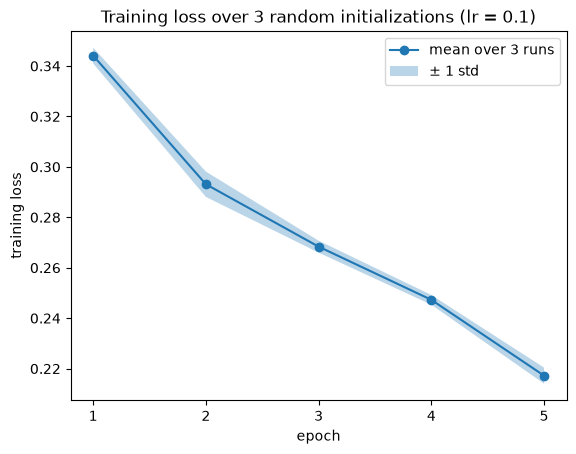

mean [0.34412785 0.29311041 0.26836654 0.24727829 0.21721318]
std  [0.00312529 0.00502548 0.00237323 0.00193012 0.00318987]


In [52]:
runs = []
for seed in [0, 1, 2]:
    print('seed', seed)
    h = train(0.1, seed, xtrain, ytrain, xval, yval)
    runs.append(h['train_loss'])

runs = np.array(runs)              # shape (3, 5): 3 runs x 5 epochs
mean = runs.mean(axis=0)           # average over the runs, per epoch
std = runs.std(axis=0)

epochs = range(1, 6)
plt.plot(epochs, mean, marker='o', label='mean over 3 runs')
plt.fill_between(epochs, mean - std, mean + std, alpha=0.3, label='± 1 std')
plt.xlabel('epoch')
plt.ylabel('training loss')
plt.title('Training loss over 3 random initializations (lr = 0.1)')
plt.xticks(epochs)
plt.legend()
plt.savefig('q8_seeds.pdf')
plt.show()

print('mean', mean)
print('std ', std)

lr 0.001
epoch 1: train loss 2.1573, val loss 2.1564, val acc 0.4666
epoch 2: train loss 2.0064, val loss 2.0069, val acc 0.6160
epoch 3: train loss 1.8512, val loss 1.8524, val acc 0.6664
epoch 4: train loss 1.6944, val loss 1.6964, val acc 0.7044
epoch 5: train loss 1.5425, val loss 1.5458, val acc 0.7294
lr 0.003
epoch 1: train loss 1.8520, val loss 1.8522, val acc 0.6488
epoch 2: train loss 1.4026, val loss 1.4067, val acc 0.7502
epoch 3: train loss 1.0747, val loss 1.0804, val acc 0.7964
epoch 4: train loss 0.8741, val loss 0.8806, val acc 0.8184
epoch 5: train loss 0.7481, val loss 0.7558, val acc 0.8346
lr 0.01
epoch 1: train loss 0.9987, val loss 1.0035, val acc 0.7992
epoch 2: train loss 0.6241, val loss 0.6328, val acc 0.8480
epoch 3: train loss 0.4989, val loss 0.5065, val acc 0.8692
epoch 4: train loss 0.4409, val loss 0.4483, val acc 0.8792
epoch 5: train loss 0.4041, val loss 0.4120, val acc 0.8858
lr 0.03
epoch 1: train loss 0.5042, val loss 0.5101, val acc 0.8654
epoch 

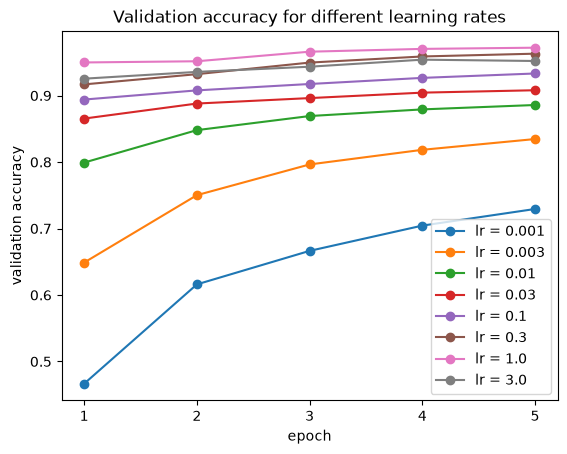

lr 0.001: final val loss 1.5458, final val acc 0.7294
lr 0.003: final val loss 0.7558, final val acc 0.8346
lr 0.01: final val loss 0.4120, final val acc 0.8858
lr 0.03: final val loss 0.3131, final val acc 0.9080
lr 0.1: final val loss 0.2318, final val acc 0.9332
lr 0.3: final val loss 0.1228, final val acc 0.9630
lr 1.0: final val loss 0.0955, final val acc 0.9720
lr 3.0: final val loss 0.1731, final val acc 0.9520


In [56]:
lrs = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
results = {}
for lr in lrs:
    print('lr', lr)
    results[lr] = train(lr, 0, xtrain, ytrain, xval, yval)

epochs = range(1, 6)
for lr in lrs:
    plt.plot(epochs, results[lr]['val_acc'], marker='o', label=f'lr = {lr}')
plt.xlabel('epoch')
plt.ylabel('validation accuracy')
plt.title('Validation accuracy for different learning rates')
plt.xticks(epochs)
plt.legend()
plt.savefig('q8_lr.pdf')
plt.show()

for lr in lrs:
    print(f"lr {lr}: final val loss {results[lr]['val_loss'][-1]:.4f}, "
          f"final val acc {results[lr]['val_acc'][-1]:.4f}")

In [57]:
(xfull, yfull), (xtest, ytest), _ = load_mnist(final=True)
xfull = xfull / 255
xtest = xtest / 255

final = train(1.0, 0, xfull, yfull, xtest, ytest)
print('test accuracy:', final['val_acc'][-1])

epoch 1: train loss 0.1553, val loss 0.1626, val acc 0.9498
epoch 2: train loss 0.1003, val loss 0.1168, val acc 0.9643
epoch 3: train loss 0.0699, val loss 0.0917, val acc 0.9704
epoch 4: train loss 0.0567, val loss 0.0858, val acc 0.9730
epoch 5: train loss 0.0460, val loss 0.0825, val acc 0.9746
test accuracy: 0.9746
